# Customer Shopping Behavior Analysis

## Project Overview
This project analyzes customer shopping behavior using Python to identify purchasing patterns, product preferences, seasonal trends, and customer spending habits. The analysis aims to generate actionable business insights to support data-driven decision-making.

## Business Objectives
- Identify popular product categories and products.
- Analyze customer demographics and spending patterns.
- Evaluate seasonal sales performance.
- Examine discounts and subscription behavior.
- Understand shipping and payment preferences.
- Provide data-driven business recommendations.

## Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## Setup and Data Loading
Import the libraries and load the dataset. In Colab, upload `shopping_trends_updated.csv` to the session before running the notebook.

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
data=pd.read_csv("/content/shopping_trends_updated.csv")
data

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,2-Day Shipping,No,No,32,Venmo,Weekly
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Standard,No,No,24,Venmo,Quarterly
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,Express,No,No,24,Venmo,Weekly


## Data Understanding
Inspect the dataset structure, data types and descriptive statistics.

In [65]:
data.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [66]:
data.tail()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,4.2,No,2-Day Shipping,No,No,32,Venmo,Weekly
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,4.5,No,Store Pickup,No,No,41,Bank Transfer,Bi-Weekly
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,2.9,No,Standard,No,No,24,Venmo,Quarterly
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,3.8,No,Express,No,No,24,Venmo,Weekly
3899,3900,52,Female,Handbag,Accessories,81,California,M,Beige,Spring,3.1,No,Store Pickup,No,No,33,Venmo,Quarterly


In [67]:
data.shape

(3900, 18)

In [68]:
data.columns

Index(['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category',
       'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season',
       'Review Rating', 'Subscription Status', 'Shipping Type',
       'Discount Applied', 'Promo Code Used', 'Previous Purchases',
       'Payment Method', 'Frequency of Purchases'],
      dtype='object')

In [125]:
data.dtypes

,0
Customer ID,int64
Age,int64
Gender,object
Item Purchased,object
Category,object
Purchase Amount (USD),int64
Location,object
Size,object
Color,object
Season,object


In [69]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [130]:
#Numerical and categorical columns
data.select_dtypes(include='object').columns

Index(['Gender', 'Item Purchased', 'Category', 'Location', 'Size', 'Color',
       'Season', 'Subscription Status', 'Shipping Type', 'Discount Applied',
       'Promo Code Used', 'Payment Method', 'Frequency of Purchases'],
      dtype='object')

In [131]:
data.select_dtypes(include='number').columns

Index(['Customer ID', 'Age', 'Purchase Amount (USD)', 'Review Rating',
       'Previous Purchases'],
      dtype='object')

In [70]:
data.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [127]:
data.nunique()

,0
Customer ID,3900
Age,53
Gender,2
Item Purchased,25
Category,4
Purchase Amount (USD),81
Location,50
Size,4
Color,25
Season,4


In [128]:
data['Category'].nunique()

4

In [83]:
#Identify the unique values in these columns:
# - Gender
# - Category
# - Season
# - Subscription Status
data['Gender'].unique()
data['Category'].unique()
data['Season'].unique()
data['Subscription Status'].unique()

array(['Yes', 'No'], dtype=object)

### Initial Observations

- The dataset contains 3,900 records and 18 columns.
- It contains both numerical and categorical variables.
- Numerical attributes include Age, Purchase Amount,
  Previous Purchases, and Review Rating.
- Categorical attributes include Gender, Category,
  Season, Subscription Status, and Shipping Type.
- The dataset provides information suitable for analyzing
  customer demographics, spending behavior, and product
  preferences.

## Data Quality and Validation
Check missing values, duplicates, numerical ranges and categorical values.

In [71]:
data.isna().sum() #to find count of null values in each column
#data['Age'].isna().sum() #to find count of null values in particular column

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


In [72]:
d=data.duplicated().sum()
d

np.int64(0)

In [84]:
#Age validation
data['Age'].min() #18
data['Age'].max() #70

70

In [85]:
#Q2. Purchase amount validation
data['Purchase Amount (USD)'].min() #20
data['Purchase Amount (USD)'].max() #100

100

In [86]:
#Review rating validation
data['Review Rating'].min() #2.5
data['Review Rating'].max() #5.0

5.0

In [88]:
#Q5. Category validation

# Check whether any unexpected values exist in the Discount Applied and Promo Code Used columns
data['Discount Applied'].unique() #array(['Yes', 'No'], dtype=object)
data['Promo Code Used'].unique() #array(['Yes', 'No'], dtype=object)

array(['Yes', 'No'], dtype=object)

In [89]:
#Identify customers whose age is below 18, if any.
data[data['Age']<18]

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases


### Data Quality Summary
The recorded checks found no missing values or duplicate rows. Ages range from 18 to 70, purchase amounts from $20 to $100, and review ratings from 2.5 to 5.0. No cleaning modifications were required based on these checks.

## Exploratory Data Analysis
### Customer and Shopping Overview

In [90]:
#Q1. Customer demographics

# How many customers are there in each gender?
data['Gender'].value_counts()

,count
Gender,
Male,2652
Female,1248


In [91]:
#Q2. Customer distribution

# How many customers belong to each category? (Clothing, Footwear, etc.)
data['Category'].value_counts()

,count
Category,
Clothing,1737
Accessories,1240
Footwear,599
Outerwear,324


In [92]:
#Q3. Product popularity

# Which 10 items are purchased most frequently?
data['Item Purchased'].value_counts().head(10)

,count
Item Purchased,
Blouse,171
Pants,171
Jewelry,171
Shirt,169
Dress,166
Sweater,164
Jacket,163
Coat,161
Sunglasses,161


In [93]:
#Q4. Seasonal behavior

# How many purchases occur in each season?
data['Season'].value_counts()

,count
Season,
Spring,999
Fall,975
Winter,971
Summer,955


In [94]:
#Q5. Customer subscription

# How many customers are subscribed vs. not subscribed?
data['Subscription Status'].value_counts()

,count
Subscription Status,
No,2847
Yes,1053


In [95]:
#Q6. Overall spending

# Calculate the total purchase amount across all records.

data['Purchase Amount (USD)'].sum()

np.int64(233081)

In [96]:
# Q7. Average spending

# Calculate the overall average purchase amount.

data['Purchase Amount (USD)'].mean()

np.float64(59.76435897435898)

In [97]:
# Q8. Customer ratings

# Calculate the average review rating across all customers.

data['Review Rating'].mean()

np.float64(3.7499487179487176)

### Customer Spending and Product Performance

In [133]:
data.groupby('Category')['Purchase Amount (USD)'].mean()

,Purchase Amount (USD)
Category,
Accessories,59.838710
Clothing,60.025331
Footwear,60.255426
Outerwear,57.172840


In [99]:
#Q1. Category revenue

# Calculate the total purchase amount for each product category. Which category generates the most revenue?

data.groupby('Category')['Purchase Amount (USD)'].sum()


,Purchase Amount (USD)
Category,
Accessories,74200
Clothing,104264
Footwear,36093
Outerwear,18524


In [100]:
# Q2. Average spending by gender

# Find the average purchase amount for Male and Female customers. Is there a difference?

data.groupby('Gender')['Purchase Amount (USD)'].mean()

,Purchase Amount (USD)
Gender,
Female,60.249199
Male,59.536199


In [ ]:
# Q3. Spending by subscription status

# Compare the average purchase amount of subscribed customers versus non-subscribed customers.

data.groupby('Subscription Status')['Purchase Amount (USD)'].mean() # Small observed difference in average spending

In [102]:
# Q4. Average rating by category

# Find the average review rating for each category. Which category has the highest average rating?

data.groupby('Category')['Review Rating'].mean()

,Review Rating
Category,
Accessories,3.768629
Clothing,3.723143
Footwear,3.790651
Outerwear,3.746914


In [103]:
# Q5. Purchase frequency

# Find how many customers/records belong to each Frequency of Purchases group.

data.groupby('Frequency of Purchases')['Customer ID'].count()

,Customer ID
Frequency of Purchases,
Annually,572
Bi-Weekly,547
Every 3 Months,584
Fortnightly,542
Monthly,553
Quarterly,563
Weekly,539


In [105]:
# in which location which category selling most
data.groupby(['Location','Category'])['Purchase Amount (USD)'].sum().sort_values(ascending=False).head(10)

,,Purchase Amount (USD)
Location,Category,
Montana,Clothing,2768
California,Clothing,2740
Louisiana,Clothing,2562
Minnesota,Clothing,2518
Nevada,Clothing,2515
Illinois,Clothing,2508
Idaho,Clothing,2472
Oklahoma,Clothing,2464
Vermont,Clothing,2426


In [106]:
#gender buying which category mostly
data.groupby(['Gender','Category']).size().sort_values(ascending=False)

Gender  Category   
Male    Clothing       1181
        Accessories     848
Female  Clothing        556
Male    Footwear        400
Female  Accessories     392
Male    Outerwear       223
Female  Footwear        199
        Outerwear       101
dtype: int64

### Seasonal Performance, Promotions and Customer Preferences

In [107]:
#Q1. Seasonal spending
# Calculate the total purchase amount for each season.
data.groupby('Season')['Purchase Amount (USD)'].sum()

,Purchase Amount (USD)
Season,
Fall,60018
Spring,58679
Summer,55777
Winter,58607


In [ ]:
#Q2. Average spending by season
# Find the average purchase amount in Winter, Spring, Summer and Fall.
data.groupby('Season')['Purchase Amount (USD)'].mean()

In [109]:
#Q3. Discount analysis
# Compare the average purchase amount of customers who received a discount (Yes vs No).
data.groupby('Discount Applied')['Purchase Amount (USD)'].mean()

,Purchase Amount (USD)
Discount Applied,
No,60.130454
Yes,59.279070


In [110]:
#Q4. Promo code analysis
# Compare the average purchase amount of customers who used a promo code (Yes vs No).
data.groupby('Promo Code Used')['Purchase Amount (USD)'].mean()

,Purchase Amount (USD)
Promo Code Used,
No,60.130454
Yes,59.279070


In [111]:
#Q5. Payment preferences
# Find the number of purchases made using each payment method.
data.groupby('Payment Method')['Purchase Amount (USD)'].count()

,Purchase Amount (USD)
Payment Method,
Bank Transfer,612
Cash,670
Credit Card,671
Debit Card,636
PayPal,677
Venmo,634


In [112]:
#Q6. Shipping preferences
# Find the number of purchases for each shipping type.
data.groupby('Shipping Type')['Purchase Amount (USD)'].count().sort_values(ascending=False)

,Purchase Amount (USD)
Shipping Type,
Free Shipping,675
Standard,654
Store Pickup,650
Next Day Air,648
Express,646
2-Day Shipping,627


In [113]:
#Do customers with a subscription have different shopping frequency patterns from non-subscribers?
data.groupby(['Subscription Status','Frequency of Purchases'])['Customer ID'].count()
data.groupby('Subscription Status')['Frequency of Purchases'].value_counts()
#calculate the frequency distribution as percentages within each subscription status rather than counts.
data.groupby('Subscription Status')['Frequency of Purchases'].value_counts(normalize=True) * 100

Subscription Status  Frequency of Purchases
No                   Every 3 Months            15.103618
                     Quarterly                 14.857745
                     Annually                  14.471373
                     Bi-Weekly                 14.295750
                     Monthly                   14.190376
                     Fortnightly               13.663505
                     Weekly                    13.417633
Yes                  Annually                  15.194682
                     Weekly                    14.909782
                     Every 3 Months            14.624881
                     Fortnightly               14.529915
                     Monthly                   14.150047
                     Bi-Weekly                 13.295347
                     Quarterly                 13.295347
Name: proportion, dtype: float64

### Spending Distribution and Age Relationship
Two NumPy calculations complement the spending analysis and age visualization. Percentiles summarize the distribution; correlation measures the linear relationship between age and spending.

In [ ]:
np.percentile(data['Purchase Amount (USD)'], [25, 50, 75])

In [ ]:
np.corrcoef(data['Age'], data['Purchase Amount (USD)'])[0, 1]

## Data Visualization

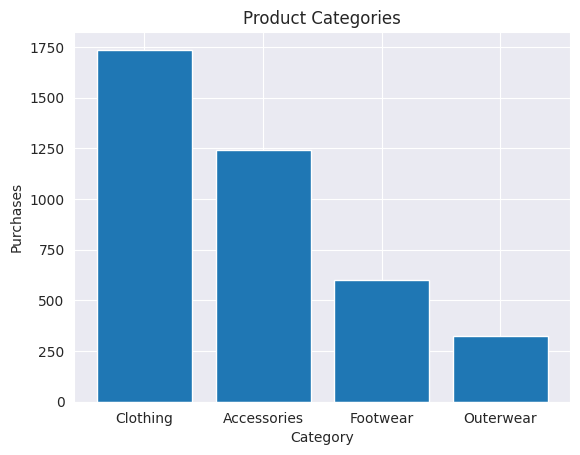

In [114]:
# Which product categories have the most purchases?
# v=data['Category'].unique()
g=data['Category'].value_counts()
#or
plt.bar(g.index,g.values)

# plt.bar(v,g)
plt.title('Product Categories')
plt.xlabel('Category')
plt.ylabel('Purchases')
plt.show()

In [ ]:
#Which season generates the highest total revenue?
sns.barplot(data=data,
            x='Season',
            y='Purchase Amount (USD)',
            estimator=sum,
            errorbar=None,
            color='skyblue',
            edgecolor='blue',
            alpha=0.8
            )
plt.title('Total Revenue by Season')
plt.xlabel('Season')
plt.ylabel('Total Revenue (USD)')
plt.show()

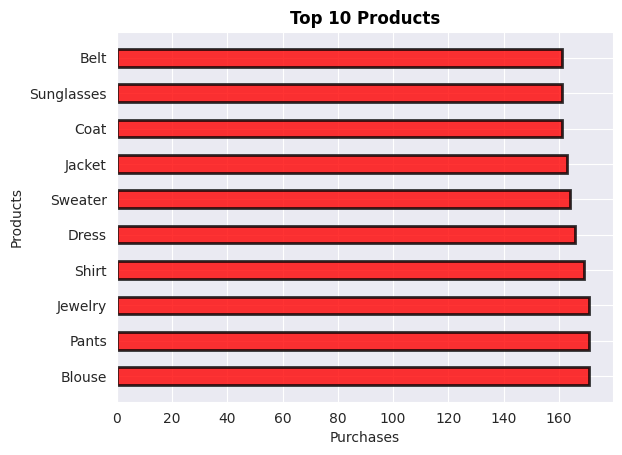

In [116]:
#Which 10 products are purchased most frequently?
b=data['Item Purchased'].value_counts().head(10)
plt.barh(b.index,b.values,
         color='red',
         height=0.5,
         edgecolor='black',
         alpha=0.8,
         linewidth=2
  )
plt.title('Top 10 Products',
          color='black',
          fontweight='bold')
plt.xlabel('Purchases')
plt.ylabel('Products')

plt.show()


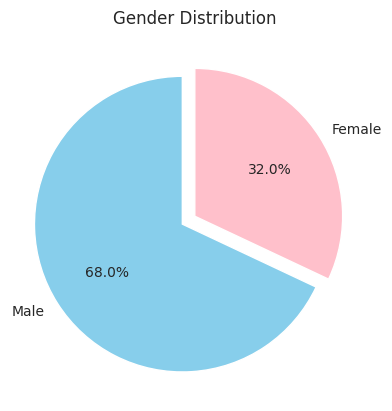

In [117]:
#What percentage of shopping records belongs to each gender?
c=data['Gender'].value_counts()
plt.pie(c,
        labels=c.index,
        autopct='%1.1f%%',
        startangle=90,
        colors=['skyblue','pink'],
        explode=[0.1,0])
plt.title('Gender Distribution')
plt.show()

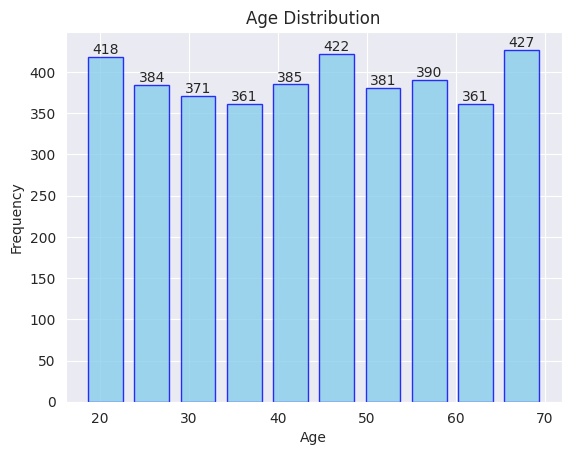

In [118]:
#Which age groups appear most frequently in our shopping dataset?
v=data['Age']
counts, bins, bars =plt.hist(v,
         bins=10,
         color='skyblue',
         edgecolor='blue',
         alpha=0.8,
         rwidth=0.75
         )
plt.title('Age Distribution')
plt.bar_label(bars)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

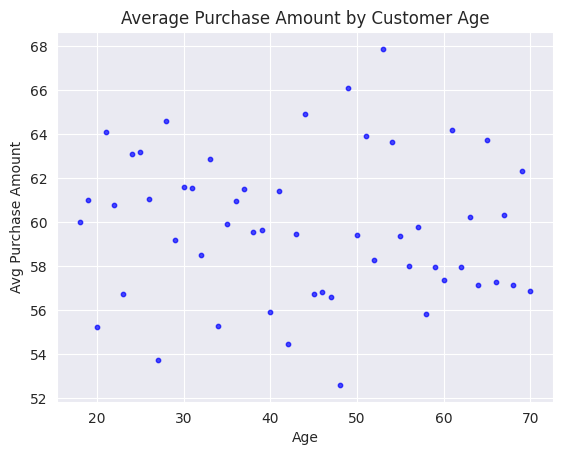

In [119]:
#Does customer age have any relationship with purchase amount?
o=data.groupby('Age')['Purchase Amount (USD)'].mean()
plt.scatter(o.index,
            o.values,
            s=10,
            c='blue',
            marker='o',
            alpha=0.7)
plt.title('Average Purchase Amount by Customer Age')
plt.xlabel('Age')
plt.ylabel('Avg Purchase Amount')
plt.show()

In [ ]:
#How does customer spending vary across different product categories?
data['Category'].unique()
clothing = data[data['Category'] == 'Clothing']['Purchase Amount (USD)']
footwear = data[data['Category'] == 'Footwear']['Purchase Amount (USD)']
accessories = data[data['Category'] == 'Accessories']['Purchase Amount (USD)']
outerwear = data[data['Category'] == 'Outerwear']['Purchase Amount (USD)']
plt.boxplot([clothing, footwear, accessories, outerwear],
           labels=['Clothing', 'Footwear', 'Accessories', 'Outerwear'],
           patch_artist=True,
            vert=True,
            showfliers=False,
            showcaps=True
            #showmeans=True
            )
plt.title('Purchase Amount by Category')
plt.xlabel('Category')
plt.ylabel('Purchase Amount')
plt.show()



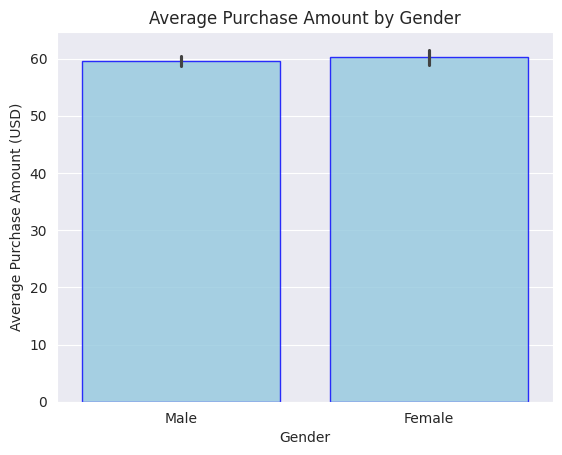

In [121]:
sns.barplot(
    data=data,
    x='Gender',
    y='Purchase Amount (USD)',
    color='skyblue',
    edgecolor='blue',
    alpha=0.8
)
sns.set_style('darkgrid')


plt.title('Average Purchase Amount by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Purchase Amount (USD)')
plt.show()

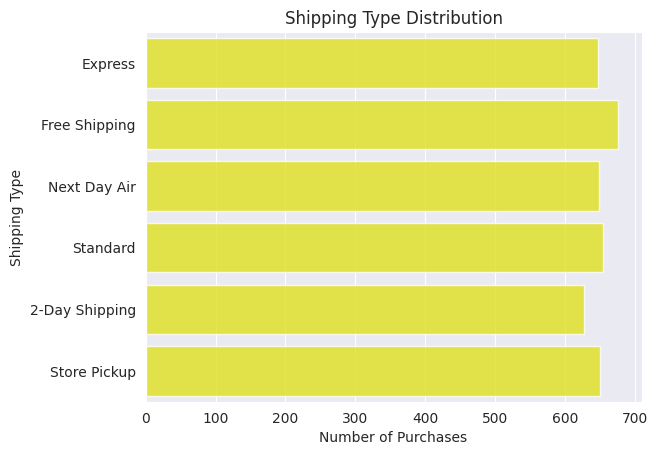

In [122]:
#Which shipping method is most frequently used by customers?
sns.countplot(
    data=data,
    y='Shipping Type',
    color='yellow',
    alpha=0.8
)

plt.title('Shipping Type Distribution')
plt.xlabel('Number of Purchases')
plt.ylabel('Shipping Type')
plt.show()

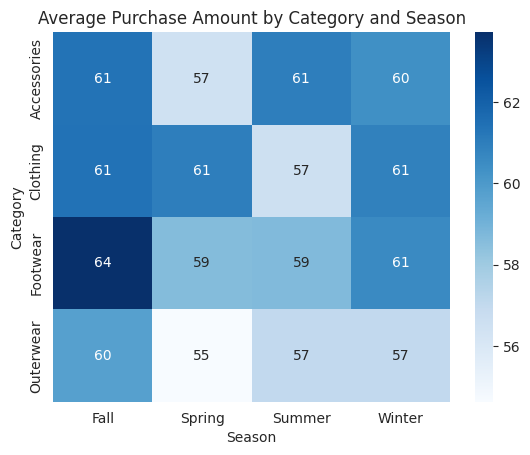

In [123]:
#How does average purchase amount vary across product categories and seasons?
h=data.groupby(['Category','Season'])['Purchase Amount (USD)'].mean().unstack()
sns.heatmap(data=h,annot=True,cmap='Blues')
plt.title('Average Purchase Amount by Category and Season')
plt.xlabel('Season')
plt.ylabel('Category')
plt.show()

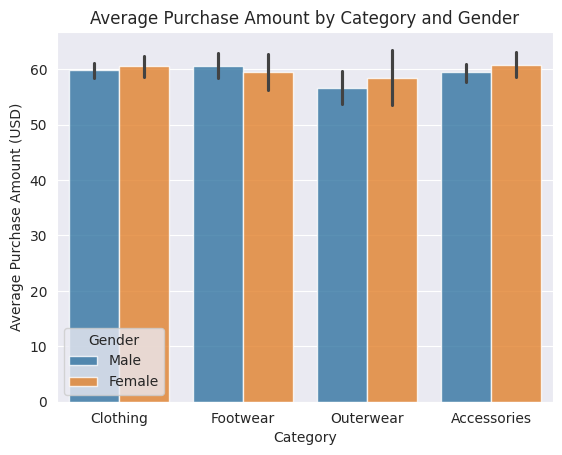

In [124]:
#How does average purchase amount vary by product category and gender?
sns.barplot(data=data,
            x='Category',
            y='Purchase Amount (USD)',
            hue='Gender',
            alpha=0.8
            )
plt.title('Average Purchase Amount by Category and Gender')

plt.xlabel('Category')
plt.ylabel('Average Purchase Amount (USD)')
plt.show()


## Key Findings and Business Recommendations

**KPI summary:** 3,900 shopping records; $233,081 total recorded purchase amount; $59.76 average purchase amount; 3.75/5 average review rating.

- **Product demand:** Clothing is the most frequently purchased category and generates $104,264 in recorded revenue. Accessories ranks second in purchase frequency for both genders. Prioritize inventory availability for Clothing while monitoring other categories.
- **Location:** Montana has the highest Clothing revenue among the displayed top location-category combinations. Investigate local demand before allocating additional inventory.
- **Seasonality:** Fall leads with $60,018, while Summer has the lowest recorded revenue ($55,777). Explore targeted Summer promotions and evaluate their results.
- **Customer targeting:** Average spending by gender is relatively similar; use observed product preferences rather than gender alone to guide marketing.
- **Discounts:** Average spending is $59.28 with discounts versus $60.13 without. This small observed difference does not establish causation; evaluate promotions by product category and customer group.
- **Subscriptions:** Weekly purchasing is reported by 14.91% of subscribers and 13.42% of non-subscribers. Investigate loyalty benefits further rather than assuming subscriptions increase frequency.
- **Shipping:** Free Shipping leads with 675 records, compared with 627 for 2-Day Shipping. Retain options until costs, profitability and customer satisfaction can be evaluated.

## Limitations and Conclusion
The analysis is descriptive and does not establish causality or statistical significance. The dataset does not provide product costs, shipping costs, discount percentages or dated transaction histories sufficient to establish profitability or recurring seasonal trends. Recorded purchase amounts are used as a revenue proxy.

This project uses Pandas for data exploration and aggregation, NumPy for spending distribution and correlation, and Matplotlib and Seaborn for visualization. The findings support inventory planning, seasonal marketing and further evaluation of customer loyalty and shipping strategies.

## Revision Notes

- Consolidated headings and moved business findings after the analysis and charts.
- Removed repeated missing-value, duplicate, descriptive-statistics, category-count, column-list and preview checks, and a repeated overall mean expression.
- Restored the commented-out seasonal average calculation; the payment count is already covered separately.
- Added `estimator=sum` and `errorbar=None` to the seasonal revenue chart so it shows totals rather than means.
- Replaced the unsupported statistical-significance comment with a descriptive comment and corrected the Outerwear chart label.
- Added two NumPy cells: purchase amount quartiles and age/spending correlation.
- Added KPI summary, recommendations, limitations and conclusion.

Existing unchanged outputs are retained. New or corrected calculation cells need to be run in Colab with the original CSV. The notebook has been structurally validated but not rerun against the CSV.
